
## Алфавит, на котором написан текст


In [23]:
alphabet = 'абвгдежзийклмнопрстуфхцчшщъыьэюя'

##  Подсчёт биграм с прошлой лабораторной

In [17]:
import itertools

def create_frequency_dictionary(alphabet, m):
    if m < 3:
        combination_frequency = {"".join(i): 0 for i in itertools.product(alphabet, repeat=m)}
        return combination_frequency
    else: return {}

def count_mgram(text, alphabet, m):
    mgram = ''
    num_mgrams = 0
    combination_count = create_frequency_dictionary(alphabet, m)
    for letter in text:
        if letter in alphabet:
            if len(mgram) < m:
                mgram += letter
            else:
                mgram = mgram[1:] + letter
            if len(mgram) == m:
                num_mgrams += 1
                if combination_count.get(mgram) is not None: combination_count[mgram] += 1
                else: combination_count[mgram] = 0
        else:
            mgram = ''
    return combination_count, num_mgrams


## Работа с таблицей

### Иниациализация таблицы

In [18]:
def create_table(alphabet, text, m, reference=False, cipher_num_mgrams=1):
    alphabet_length = len(alphabet)
    bigrams, num_mgrams = count_mgram(text, alphabet, m)
    if not reference:
        coefficient = 1
    else:
        coefficient =  cipher_num_mgrams / num_mgrams
    bigram_keys = list(bigrams)
    table = [[0 for _ in range(alphabet_length)] for _ in range(alphabet_length)]
    for i in range(alphabet_length):
        for j in range(alphabet_length):
            table[i][j] = bigrams[bigram_keys[i*alphabet_length + j]] * coefficient
    return table, num_mgrams


### Перестановка букв в таблице

In [19]:
def change_ij(table, i, j):
    table[i], table[j] = table[j], table[i]
    for row in table:
        row[i], row[j] = row[j], row[i]
    return table


### Вычисление суммы

In [20]:
def func_jacobson(table_T, table_B):
    result = 0
    for i in range(len(table_T)):
        for j in range(len(table_T)):
            result += abs(table_T[i][j] - table_B[i][j])
    return result

## Алгоритм Якобсона

In [21]:
from random import shuffle, choices

def add_handmade_analysise(alphabet, key, alphabet_letters, key_letters):
    assert len(alphabet_letters) == len(key_letters)
    for i, j in zip(alphabet_letters, key_letters):
        i_index = alphabet.index(i)
        j_index = alphabet.index(j)
        key[i_index], key[j_index] = j, i
    return key


def jacobson(text, reference_text, alphabet, m, alphabet_letters=None, key_letters=None):
    mgrams, _ = count_mgram(reference_text, alphabet, 1)
    mgrams = dict(sorted(mgrams.items(), key=lambda item: item[1], reverse=True))
    key = list(mgrams.keys())
    if alphabet_letters is not None and key_letters is not None:
        key = add_handmade_analysise(alphabet, key, alphabet_letters, key_letters)
    # key = list("ачвгдежсийулмношрзькфхцбпщъытэюя")
    # shuffle(key)
    for i, letter in enumerate(text):
        if letter in alphabet:
            text = text[:i] + key[alphabet.index(letter)] + text[i + 1:]
    T, cipher_num_mgrams = create_table(alphabet, text, m)
    B, _ = create_table(alphabet, reference_text, m, reference=True, cipher_num_mgrams=cipher_num_mgrams)
    v_old = func_jacobson(T, B)
    count = 0
    while count != 10000:
        letter_i, letter_j = choices(key, k=2)
        i, j = key.index(letter_i), key.index(letter_j)
        if alphabet_letters is not None and key_letters is not None:
            if letter_i in key_letters or letter_j in key_letters:
                continue
        T = change_ij(T, i, j)
        v_new = func_jacobson(T, B)
        if v_new < v_old:
            key[i], key[j] = key[j], key[i]
            count = 0
            v_old = v_new
        else:
            count += 1
    # for i in T:
    #     print(i)
    # for j in B:
    #     print(j)
    return key


## Main
### Ручной взлом


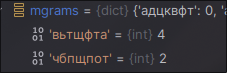

как видно на скрине, самое встречаемое 7 буквенное слово - "вьтщфта", предположим это "Штирлиц"

При анализе трёхграмм видно

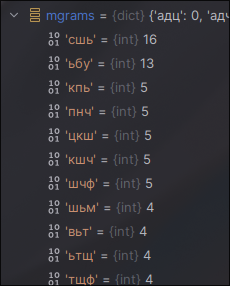

Предположим "сшь" - "зпт", "ьбу" - "тчк"



Предпроложим это форма слова "прочитав"



видим "А Штирлиц получил шифровку"



"открывая"



"русский разведчик Исаев"



На полу среди бутылок из-под водки



э -> г, х ->  м

In [24]:
import json
from IPython.display import HTML

with open('../files/2B.txt', 'r', encoding='cp866') as f:
    cipher = f.read().lower().replace(' ', '').replace('\n', '')[30:]
with open('../files/anime_text', 'r', encoding='utf-8') as f:
    reference_text = f.read().lower().replace('ё', 'е').replace(' ', '').replace('\n', '')

mgrams, _ = count_mgram(cipher, 'абвгдежзийклмнопрстуфхцчшщъыьэюя', 1)
mgrams = dict(sorted(mgrams.items(), key=lambda item: item[1], reverse=True))
# alphabet = list(mgrams.keys())

# alphabet
# with open('mgrams', 'w', encoding='utf-8') as f:
#     json.dump(mgrams, f, indent=4, ensure_ascii=False)
# reference_mgrams, _ = count_mgram(reference_text, alphabet, 1)
# reference_mgrams = dict(sorted(reference_mgrams.items(), key=lambda item: item[1], reverse=True))
#
# with open('reference_mgrams', 'w', encoding='utf-8') as f:
#     json.dump(reference_mgrams, f, indent=4, ensure_ascii=False)
# key = jacobson(cipher, reference_text, alphabet, 2)
key = list("цчшщыьэюяйабвгдежзиклмнопръстуфх")
decrypted_text = ''
for i in cipher:
    if i in alphabet:
        decrypted_text += key[alphabet.index(i)]
    else: decrypted_text += i
decrypted_text = decrypted_text.replace('тчк', ". ").replace("зпт", ", ")
print(decrypted_text)

# find_letters = "тчкзпширлцоауфвыесднбгмьхящюжэ"
check_mgrams, _ = count_mgram(decrypted_text, alphabet, 1)
check_mgrams = dict(sorted(check_mgrams.items(), key=lambda item: item[1], reverse=True))
#
# highlight_color = "red"
#
# # Формируем строку
# colored_text = ""
# for letter in decrypted_text:
#     if letter in find_letters:
#         colored_text += f'<span style="color:{highlight_color}">{letter}</span>'
#     else:
#         colored_text += letter
# HTML(colored_text)

гитлерпринимаетвсвоемкабинетемуссолини. вдругдверьраспахивается, входитштирлиц, нинакогонеобращаявнимания, подходитксеифу, открываетегосвоимключоминачинаетрытьсявнем, выбрасываяненужныедокументынапол. ктоэтоудивленноспрашиваетдуче. русскииразведчикисаев, безразличнымтономотвечаетфюрер, унасштирлицемчислится. такпочемужетыегонеарестуешьа, всеравноотвертится. кконцувоиныположениегерманиибылостольплачевно, чтодажевреихсканцелярииприходилосьстоятьвочередидлятого, чтобыкупитьколбасы. однакоштирлиц, вопрекивсемнормамповедения, всегдабралбезочереди. гестаповцыоченьвозмущалисьэтим. ониещенезнали, чтогероисоветскогосоюзаобслуживаютсявнеочереди. аштирлицполучилшифровку. прочитав, онеесжег, послечегоплюнулнаполивысморкалсявзанавеску. вшифровкебылонаписанозаданиевыполнено, можнонемногорасслабиться. бштирлицнеделюнепоявлялсянаработе. посланныенапоискигестаповцынашлиегонадаче, напившегосядобесчувствияилежащегонаполусредибутылокизподводки. 
